# ⚡ Practical 10 — Baselines & Evaluation

**Topic:** What makes one electricity-demand forecast better than another?


**How to work:** Run cells from top to bottom. Most code is already written: change only values marked **✏️ CHANGE**, inspect the graphs, and type short answers in the text boxes below each task. An LLM may help you explain your results, but verify its claims with calculations.

**Learning outcomes:** (1) define a forecast horizon; (2) compare lag-1h / lag-24h / lag-168h baselines; (3) interpret MAE, RMSE, MAPE and nRMSE; (4) evaluate operationally important hours; (5) avoid time-series leakage; (6) assess a Random Forest with walk-forward validation.

> **Important comparison rule:** Here the actual prediction task is **one hour ahead**: predict consumption at hour *t* using information available before *t*. The Elering “planned consumption” column is useful for descriptive comparison, but its publication/issue time is not provided in this dataset; therefore we **do not claim** it was available with the same one-hour lead time as our baselines and ML model.


## 1. Load hourly Estonian demand
We load the Elering 2022 CSV **directly from the course GitHub repository**, without saving a local copy. The file uses a semicolon separator and a comma as decimal symbol.

We index observations by **UTC timestamps**. This preserves a regular 1-hour sequence across daylight-saving time changes. For plotting or grouping by local hour, we explicitly convert the timestamps to `Europe/Tallinn`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', 20)
plt.rcParams['figure.figsize'] = (11, 4)

DATA_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/main/data/'
    'electricity-production%20and%20consumption_2022.csv'
)
raw = pd.read_csv(DATA_URL, sep=';', decimal=',')
raw['timestamp_utc'] = pd.to_datetime(raw['Ajatempel (UTC)'], unit='s', utc=True)
raw = raw.sort_values('timestamp_utc').set_index('timestamp_utc')

energy = pd.DataFrame(index=raw.index)
energy['demand'] = pd.to_numeric(raw['Tarbimine'], errors='coerce')
energy['planned'] = pd.to_numeric(raw['Planeeritud tarbimine'], errors='coerce')
energy['local_hour'] = energy.index.tz_convert('Europe/Tallinn').hour
energy['day_of_week'] = energy.index.tz_convert('Europe/Tallinn').dayofweek

print('Rows:', len(energy))
print('Date range (UTC):', energy.index.min(), 'to', energy.index.max())
print('Missing values:', energy[['demand','planned']].isna().sum().to_dict())
print('Time-step distribution:', energy.index.to_series().diff().value_counts().head(3).to_dict())
display(energy.head())


Rows: 8760
Date range (UTC): 2021-12-31 22:00:00+00:00 to 2022-12-31 21:00:00+00:00
Missing values: {'demand': 0, 'planned': 0}
Time-step distribution: {Timedelta('0 days 01:00:00'): 8757, Timedelta('0 days 00:00:00'): 1, Timedelta('0 days 02:00:00'): 1}


,demand,planned,local_hour,day_of_week
timestamp_utc,,,,
2021-12-31 22:00:00+00:00,899.4,903.1,0,5
2021-12-31 23:00:00+00:00,892.1,935.8,1,5
2022-01-01 00:00:00+00:00,874.3,897.6,2,5
2022-01-01 01:00:00+00:00,860.1,878.5,3,5
2022-01-01 02:00:00+00:00,842.7,891.1,4,5


### ✏️ Task 1 — Check the data

1. How many hourly observations are there? How many missing demand values?
2. Why is it safer to use the UTC timestamp for `shift(24)` than local timestamps around DST transitions?
3. Does `shift(24)` always mean “same wall-clock hour yesterday” in Tallinn?

**Your answer:**

- **1:** …
- **2:** …
- **3:** …


## 2. Three reference forecasts

For each target hour *t*, a lag baseline predicts using a previously observed value. These are valid for our **one-hour-ahead** setup because all three lagged values are in the past.

- **Lag-1h:** previous hour's demand
- **Lag-24h:** demand 24 elapsed hours earlier
- **Lag-168h:** demand 168 elapsed hours earlier (one elapsed week)

Change the plotted week to a different week in 2022, rerun, and compare the shapes.


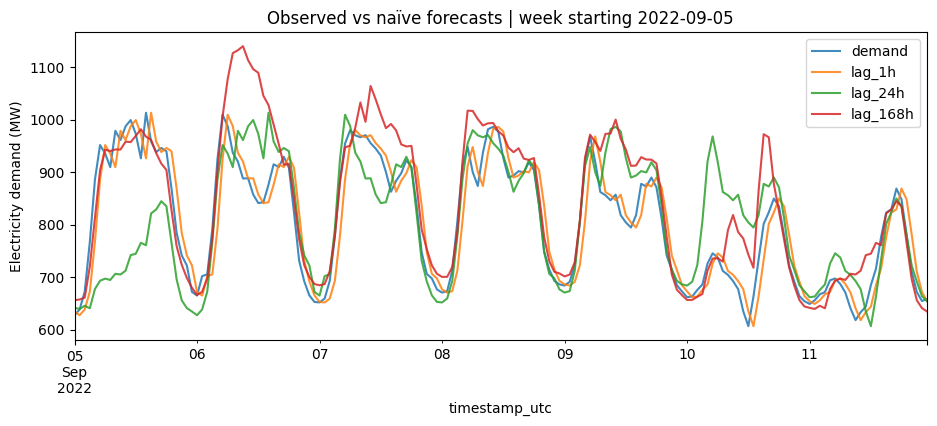

In [2]:
# ✏️ CHANGE: try other 2022 weeks, e.g. '2022-02-07' or '2022-10-24'
START_WEEK = '2022-09-05'

for hours in [1, 24, 168]:
    energy[f'lag_{hours}h'] = energy['demand'].shift(hours)

# One shared test set for every baseline; train/test separation is chronological.
split_time = pd.Timestamp('2022-09-01', tz='UTC')
valid = energy.dropna(subset=['demand', 'lag_1h', 'lag_24h', 'lag_168h']).copy()
test = valid.loc[valid.index >= split_time].copy()

week_start = pd.Timestamp(START_WEEK, tz='UTC')
week_end = week_start + pd.Timedelta(days=7)
week = test.loc[(test.index >= week_start) & (test.index < week_end)]
assert len(week) > 0, 'Select a test week on or after 2022-09-01 (UTC).'
week[['demand','lag_1h','lag_24h','lag_168h']].plot(
    title=f'Observed vs naïve forecasts | week starting {START_WEEK}',
    ylabel='Electricity demand (MW)', alpha=.85
)
plt.show()


,MAE [MW],RMSE [MW],MAPE [%],nRMSE/mean [%]
lag_1h,33.32,44.42,3.57,4.65
lag_24h,49.55,79.39,5.23,8.31
lag_168h,52.06,73.99,5.40,7.74


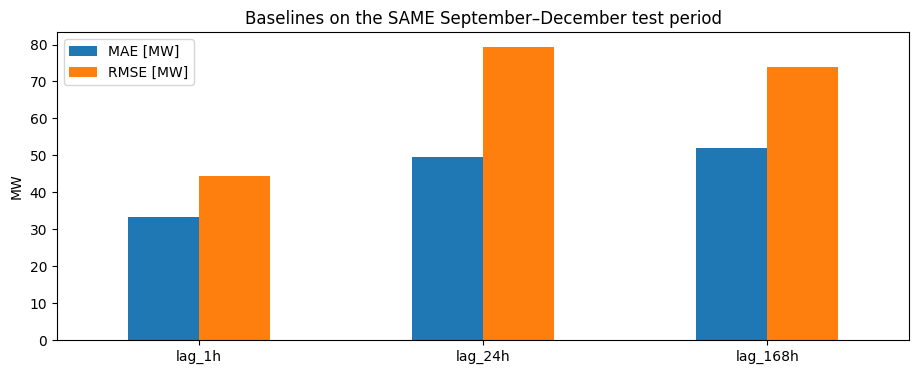

In [3]:
def score_forecast(y_true, y_pred):
    """MAE [MW], RMSE [MW], MAPE [%], and mean-normalized RMSE [%]."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    yt, yp = y_true[mask], y_pred[mask]
    if len(yt) == 0:
        raise ValueError('No valid observations')
    mae = np.mean(np.abs(yt - yp))
    rmse = np.sqrt(np.mean((yt - yp)**2))
    # Percentage-based metrics are undefined for zero observed values.
    nonzero = np.abs(yt) > 1e-12
    mape = (np.mean(np.abs((yt[nonzero] - yp[nonzero]) / yt[nonzero])) * 100
            if np.any(nonzero) else np.nan)
    scale = np.mean(np.abs(yt))
    nrmse = (100 * rmse / scale) if scale > 0 else np.nan
    return {'MAE [MW]': mae, 'RMSE [MW]': rmse,
            'MAPE [%]': mape, 'nRMSE/mean [%]': nrmse}

baseline_columns = ['lag_1h', 'lag_24h', 'lag_168h']
baseline_scores = pd.DataFrame({
    name: score_forecast(test['demand'], test[name]) for name in baseline_columns
}).T.round(2)
display(baseline_scores)

baseline_scores[['MAE [MW]', 'RMSE [MW]']].plot.bar(
    title='Baselines on the SAME September–December test period', rot=0
)
plt.ylabel('MW')
plt.show()


### ✏️ Task 2 — Evaluate baselines

**Small code edit:** In `START_WEEK`, change one date and rerun the graph. Then interpret the evaluation table.

1. Which baseline has the lowest test MAE? Does the RMSE ranking agree?
2. Why can lag-1h look excellent for one-hour-ahead forecasting but be **invalid** for a forecast issued 24 hours before the target?
3. Why are the three baselines more informative than a single number like “RMSE = 50”?

**Your answer:** …


## 3. One forecast, several metrics

The same forecasts can be ranked differently by different metrics. MAE treats errors linearly; RMSE penalizes large misses more heavily. MAPE highlights relative errors but is undefined when the actual value is zero. nRMSE only becomes meaningful when the **normalization method is specified**.


Change `SPIKE` and `BIAS` in the toy example. Can you make the metrics prefer different forecasts?


,MAE [MW],RMSE [MW],MAPE [%],nRMSE/mean [%]
A: one large miss,10.0,22.36,10.0,22.36
B: small constant bias,15.0,15.00,15.0,15.00


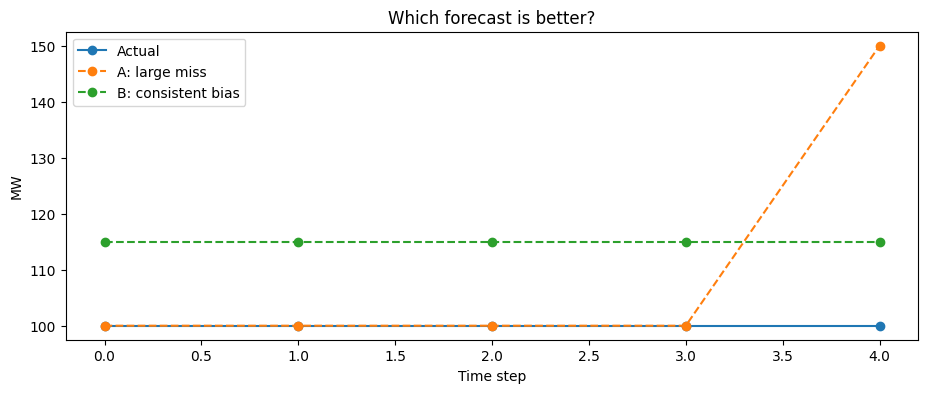

MAE winner: A: one large miss
RMSE winner: B: small constant bias


In [4]:
actual = np.array([100., 100., 100., 100., 100.])
# ✏️ CHANGE these two parameters (e.g., SPIKE=50 and BIAS=15)
SPIKE = 50.
BIAS = 15.
forecast_a = actual + np.array([0., 0., 0., 0., SPIKE])
forecast_b = actual + BIAS

toy_scores = pd.DataFrame({
    'A: one large miss': score_forecast(actual, forecast_a),
    'B: small constant bias': score_forecast(actual, forecast_b)
}).T.round(2)
display(toy_scores)

fig, ax = plt.subplots()
ax.plot(actual, 'o-', label='Actual')
ax.plot(forecast_a, 'o--', label='A: large miss')
ax.plot(forecast_b, 'o--', label='B: consistent bias')
ax.set(title='Which forecast is better?', xlabel='Time step', ylabel='MW')
ax.legend(); plt.show()

print('MAE winner:', toy_scores['MAE [MW]'].idxmin())
print('RMSE winner:', toy_scores['RMSE [MW]'].idxmin())


### ✏️ Task 3 — Are metric choices neutral?

1. With the starting parameters, which forecast wins MAE, and which wins RMSE? Explain mathematically.
2. Which metric would you prioritize if one large missed peak could cause an operational problem?
3. What happens to MAPE if a dataset contains real zeros? How should those cases be handled?

**Your answer:** …


## 4. Make the metric care about the morning peak

An electricity-system operator might care more about errors during **07:00–09:59 Tallinn time** than overnight. We can explicitly specify a domain-weighted MAE. The weight is a design decision, not a universal truth.

Change `MORNING_WEIGHT` to `1`, `3`, and `8`. The code also shows a small deterministic example where the **winner changes** when the morning peak matters more.


Weighted MAE at morning weight 3:


,Weighted MAE [MW]
lag_1h,39.58
lag_168h,51.91
lag_24h,55.46


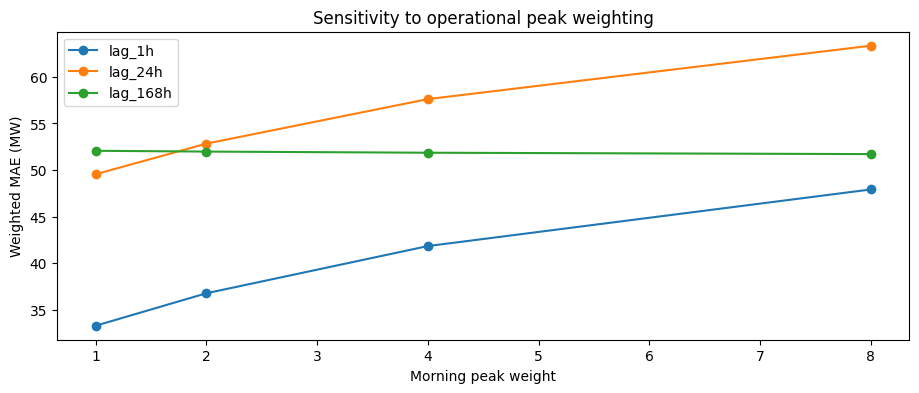

Peak weight 1: A=12.50, B=7.50, winner=B
Peak weight 3: A=6.25, B=11.25, winner=A
Peak weight 8: A=2.78, B=13.33, winner=A


In [5]:
def weighted_mae(actual, prediction, hours, peak_weight=3.0):
    y = np.asarray(actual, dtype=float)
    p = np.asarray(prediction, dtype=float)
    h = np.asarray(hours)
    weights = np.where((h >= 7) & (h < 10), peak_weight, 1.0)
    return np.average(np.abs(y - p), weights=weights)

# ✏️ CHANGE to 1, 3, or 8
MORNING_WEIGHT = 3
operational_scores = {
    name: weighted_mae(test['demand'], test[name], test['local_hour'], MORNING_WEIGHT)
    for name in baseline_columns
}
print(f'Weighted MAE at morning weight {MORNING_WEIGHT}:')
display(pd.Series(operational_scores, name='Weighted MAE [MW]').sort_values().round(2))

weights_to_test = [1, 2, 4, 8]
sweep = pd.DataFrame({
    w: {name: weighted_mae(test['demand'], test[name], test['local_hour'], w)
        for name in baseline_columns}
    for w in weights_to_test
}).T
sweep.index.name = 'Morning peak weight'
sweep.plot(marker='o', title='Sensitivity to operational peak weighting', ylabel='Weighted MAE (MW)')
plt.show()

# Controlled decision case: same target, two forecasts with errors in different hours.
decision_hours = np.array([2, 3, 7, 8, 9, 14])
decision_actual = np.full(6, 100.)
decision_a = decision_actual + np.array([25,25,0,0,0,25])  # lower peak error
decision_b = decision_actual + np.array([0,0,15,15,15,0])   # lower night error
for weight in [1, 3, 8]:
    a = weighted_mae(decision_actual, decision_a, decision_hours, weight)
    b = weighted_mae(decision_actual, decision_b, decision_hours, weight)
    print(f'Peak weight {weight}: A={a:.2f}, B={b:.2f}, winner={"A" if a < b else "B" if b < a else "tie"}')


**Optional JupyterLab interaction:** If `ipywidgets` is installed, use the slider below to inspect peak-weight sensitivity. If the widget does not render (e.g. some static Jupyter Book builds), use the four-weight static graph above instead.

In [9]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def show_morning_weight(weight):
        results = {name: weighted_mae(test['demand'], test[name],
                 test['local_hour'], weight) for name in baseline_columns}
        display(pd.Series(results, name='Weighted MAE [MW]').sort_values().round(2))

    display(widgets.interactive(show_morning_weight,
        weight=widgets.IntSlider(value=3, min=1, max=10, step=1,
                                 description='Peak weight')))
except ImportError:
    print('Optional ipywidgets is not installed. Use the static sweep above.')


interactive(children=(IntSlider(value=3, description='Peak weight', max=10, min=1), Output()), _dom_classes=('…

### ✏️ Task 4 — Design your operational metric

1. Did the real-data baseline ranking change when peak weight increased? (It is fine if it did not.)
2. Why does the toy decision case change its winner?
3. Give one reason why morning peak demand might deserve a higher penalty in a real energy-system decision, and one reason why an arbitrary weight could mislead.

**Your answer:** …


## 5. Respect time: random vs chronological split

Build a small feature table for **one-hour-ahead** demand prediction. Every lagged feature uses past observed demand; hour/day calendar values are known in advance. The random split is **only a demonstration of a questionable evaluation protocol**, not a recommended time-series workflow.

**✏️ Small change:** Switch `SPLIT_MODE` between `'random'` and `'chronological'`. Compare results, then justify which evaluation should be trusted.


Split mode: chronological
Training dates: 2022-01-07 22:00:00+00:00 → 2022-08-31 23:00:00+00:00
Test dates: 2022-09-01 00:00:00+00:00 → 2022-12-31 21:00:00+00:00


,MAE [MW],RMSE [MW],MAPE [%],nRMSE/mean [%]
Random Forest,16.59,21.68,1.77,2.27


Test lag-1h MAE: 33.32


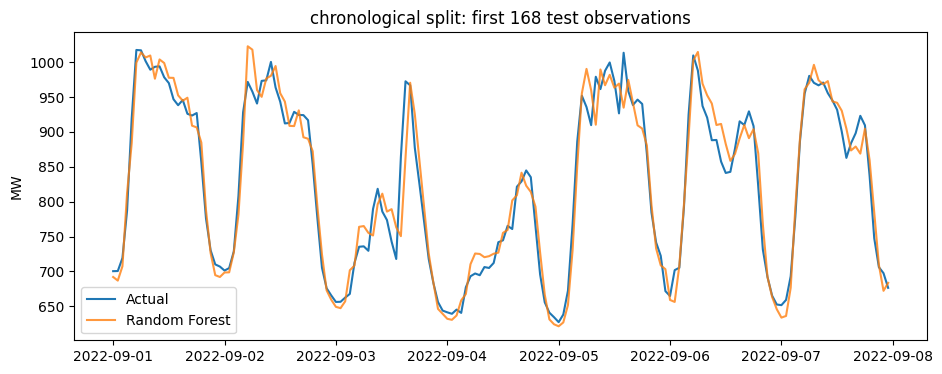

In [7]:
# Allowed information at target time t: past demand, known calendar.
model_data = energy[['demand','lag_1h','lag_24h','lag_168h','local_hour','day_of_week']].dropna().copy()
model_data['hour_sin'] = np.sin(2 * np.pi * model_data['local_hour'] / 24)
model_data['hour_cos'] = np.cos(2 * np.pi * model_data['local_hour'] / 24)
model_data['dow_sin'] = np.sin(2 * np.pi * model_data['day_of_week'] / 7)
model_data['dow_cos'] = np.cos(2 * np.pi * model_data['day_of_week'] / 7)
FEATURES = ['lag_1h','lag_24h','lag_168h','hour_sin','hour_cos','dow_sin','dow_cos']
X = model_data[FEATURES]
y = model_data['demand']

# ✏️ CHANGE: 'random' or 'chronological'
SPLIT_MODE = 'chronological'
if SPLIT_MODE == 'random':
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, shuffle=True, random_state=42
    )
elif SPLIT_MODE == 'chronological':
    mask = X.index < split_time
    X_train, X_test = X.loc[mask], X.loc[~mask]
    y_train, y_test = y.loc[mask], y.loc[~mask]
else:
    raise ValueError("SPLIT_MODE must be 'random' or 'chronological'")

rf = RandomForestRegressor(n_estimators=60, max_depth=12,
                           min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_hat = rf.predict(X_test)
print('Split mode:', SPLIT_MODE)
print('Training dates:', X_train.index.min(), '→', X_train.index.max())
print('Test dates:', X_test.index.min(), '→', X_test.index.max())
display(pd.Series(score_forecast(y_test, y_hat), name='Random Forest').to_frame().T.round(2))
print('Test lag-1h MAE:', round(score_forecast(y_test, X_test['lag_1h'])['MAE [MW]'], 2))

sample_size = min(168, len(y_test))
fig, ax = plt.subplots()
ax.plot(y_test.sort_index().iloc[:sample_size].index,
        y_test.sort_index().iloc[:sample_size].values, label='Actual')
preds = pd.Series(y_hat, index=y_test.index).sort_index()
ax.plot(preds.iloc[:sample_size].index, preds.iloc[:sample_size].values,
        label='Random Forest', alpha=.8)
ax.set(title=f'{SPLIT_MODE} split: first {sample_size} test observations', ylabel='MW')
ax.legend(); plt.show()


### ✏️ Task 5 — Catch a misleading evaluation

1. Compare the errors after executing both split modes. Is random better **in your run**? A lower error is not guaranteed: explain the risk regardless of the observed numbers.
2. Why does a random split violate realistic deployment chronology?
3. A colleague calculates `scaler.fit_transform(full_dataset)` **before** splitting. What is the problem, and what should they do instead?

**Your answer:** …


## 6. Walk-forward evaluation: expanding training windows

A single historical cutoff might be lucky or unlucky. Here we simulate four evaluation rounds: train on observations **strictly before** the origin and evaluate the next **30 days**. Training expands with each round; the model is refit each time.

Our model forecasts **one hour ahead at each test timestamp** (rolling-origin / sequential operation): `lag_1h` is assumed available immediately before predicting that hour. This is **not** a fixed 30-day-ahead forecast issued once at the fold boundary.

Change `N_TREES` or `MAX_DEPTH`, rerun, and check whether improvement is consistent across folds.


Fold windows:


,fold,train_end,test_start,test_end
0,1,2022-04-30 23:00:00+00:00,2022-05-01 00:00:00+00:00,2022-05-30 23:00:00+00:00
1,2,2022-06-30 23:00:00+00:00,2022-07-01 00:00:00+00:00,2022-07-30 23:00:00+00:00
2,3,2022-08-31 23:00:00+00:00,2022-09-01 00:00:00+00:00,2022-09-30 23:00:00+00:00
3,4,2022-10-31 23:00:00+00:00,2022-11-01 00:00:00+00:00,2022-11-30 23:00:00+00:00


MAE by fold (MW):


Model,Random Forest,lag-1h,lag-24h
Fold,,,
1,25.22,35.02,71.56
2,19.23,32.17,55.44
3,18.33,32.36,53.20
4,14.69,34.37,42.85


Mean and standard deviation over folds (MAE, MW):


Model,Random Forest,lag-1h,lag-24h
mean,19.37,33.48,55.76
std,4.37,1.43,11.87


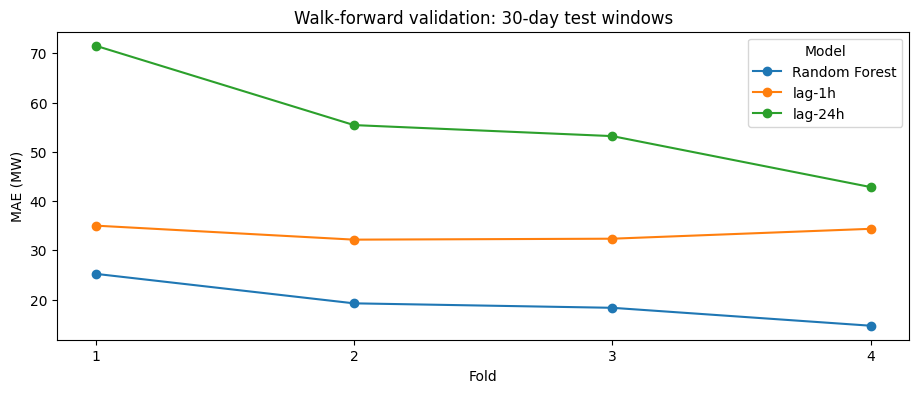

In [8]:
# ✏️ CHANGE: N_TREES = 20 or 100; MAX_DEPTH = 6 or 14
N_TREES = 60
MAX_DEPTH = 12

origins = pd.to_datetime([
    '2022-05-01', '2022-07-01', '2022-09-01', '2022-11-01'
], utc=True)
fold_results = []
fold_details = []
for fold_no, origin in enumerate(origins, start=1):
    end = origin + pd.Timedelta(days=30)
    train_mask = model_data.index < origin
    test_mask = (model_data.index >= origin) & (model_data.index < end)
    X_tr, X_te = X.loc[train_mask], X.loc[test_mask]
    y_tr, y_te = y.loc[train_mask], y.loc[test_mask]
    assert X_tr.index.max() < X_te.index.min(), 'Train/test chronology violated'
    assert X_te.index.max() < end, 'Test window exceeds intended horizon'
    model = RandomForestRegressor(n_estimators=N_TREES, max_depth=MAX_DEPTH,
                                  min_samples_leaf=3, random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)
    predictions = model.predict(X_te)
    for name, pred in [('Random Forest', predictions),
                       ('lag-1h', X_te['lag_1h']),
                       ('lag-24h', X_te['lag_24h'])]:
        scores = score_forecast(y_te, pred)
        fold_results.append({'Fold': fold_no, 'Test start': origin.strftime('%Y-%m-%d'),
                             'Model': name, **scores})
    fold_details.append({'fold': fold_no, 'train_end': X_tr.index.max(),
                         'test_start': X_te.index.min(), 'test_end': X_te.index.max()})

fold_scores = pd.DataFrame(fold_results)
mae_table = fold_scores.pivot(index='Fold', columns='Model', values='MAE [MW]')
print('Fold windows:')
display(pd.DataFrame(fold_details))
print('MAE by fold (MW):')
display(mae_table.round(2))
print('Mean and standard deviation over folds (MAE, MW):')
display(mae_table.agg(['mean','std']).round(2))
mae_table.plot(marker='o', title='Walk-forward validation: 30-day test windows',
               xticks=[1,2,3,4], ylabel='MAE (MW)')
plt.show()


### ✏️ Task 6 — Evaluate across seasons

1. Is Random Forest consistently better than **both** baselines in all four folds? Quote the actual results.
2. Why should we report variation across folds instead of only mean MAE?
3. Does a low one-hour-ahead error prove that the model is suitable for day-ahead trading? Explain.
4. How would you modify the feature set to construct a legitimate day-ahead forecast issued at a fixed time? (Conceptual answer, no code required.)

**Your answer:** …


## 7. LLM peer review: verify a confident claim

Ask an LLM the following, then **check its answer** against your tables and the experimental setup. Do not copy its response without verification.

> **Prompt to paste:** “I evaluated electricity-demand forecasts using an Elering 2022 hourly series, a one-hour rolling forecast horizon, lag-1h / lag-24h baselines, and Random Forest. Explain why a random train/test split can overstate performance, why RMSE and MAE might rank forecasts differently, and why the historical planned-demand column may not be a comparable one-hour-ahead forecast. Suggest one decision-aware evaluation metric.”

**✏️ Your task:** Identify at least **two claims to verify**. For each, say what evidence or code would confirm/refute it. If the LLM proposes comparing a day-ahead plan with a rolling one-hour model as if they had the same horizon, explain the mismatch.

**Your answer:** …


## 8. Final recommendation

Write a **5–7 sentence mini evaluation report** for an energy-system operator. Include:

1. **Horizon:** What is forecast and how far ahead?
2. **Baseline:** Which simple reference model should the proposed ML model beat?
3. **Split:** Why do you trust your chronological / walk-forward evaluation?
4. **Metrics:** At least MAE and RMSE, plus one context-sensitive indicator.
5. **Decision:** Would you deploy the Random Forest **based on this evidence**? What additional evidence is missing?

